# Chapter 14 — 지도학습 기반 공격 탐지 (실습)

## 실습 목표
1. NSL-KDD 합성 데이터 + 5개 범주 라벨
2. 전처리 Pipeline
3. LogReg / SVM / RF 학습
4. ROC-AUC, Confusion Matrix
5. pickle 저장 + 새 데이터 예측

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib
# !pip install -q seaborn
# !pip install -q scikit-learn

In [3]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, classification_report, confusion_matrix,
                             roc_curve)
rng = np.random.default_rng(42)

---
## Step 1. 데이터 준비 — NSL-KDD 합성

In [4]:
def make_rows(n, label, dur, src_b, srv, serr, proto, svc):
    return pd.DataFrame({
        'duration':     rng.exponential(scale=dur, size=n).astype(int),
        'src_bytes':    rng.integers(*src_b, size=n),
        'dst_bytes':    rng.integers(0, 100, size=n) if label != 'normal' else rng.integers(*src_b, size=n),
        'count':        rng.integers(1, 200, size=n),
        'srv_count':    rng.integers(*srv, size=n),
        'serror_rate':  rng.uniform(*serr, size=n),
        'rerror_rate':  rng.uniform(0, 0.1, size=n),
        'same_srv_rate':rng.uniform(0.8, 1.0, size=n),
        'diff_srv_rate':rng.uniform(0, 0.1, size=n),
        'protocol_type':rng.choice(proto, size=n),
        'service':      rng.choice(svc,   size=n),
        'flag':         rng.choice(['SF','S0','REJ'], size=n, p=[0.7,0.2,0.1] if label!='normal' else [0.95,0.03,0.02]),
        'label_5class': label,
    })

df_train = pd.concat([
    make_rows(10000,'normal', 5, (100, 5000), (1, 30), (0, 0.05),  ['tcp','udp','icmp'], ['http','smtp','dns']),
    make_rows( 7000,'DoS',    1, (10, 100),   (1, 200),(0.4, 0.9), ['tcp','icmp'],       ['http','ecr_i']),
    make_rows( 1700,'Probe',  1, (10, 50),    (1, 100),(0, 0.05),  ['tcp','udp'],        ['private','telnet']),
    make_rows(  200,'R2L',    20,(50, 500),   (1, 10), (0, 0.05),  ['tcp'],              ['ftp','telnet']),
    make_rows(   50,'U2R',    30,(100, 1000), (1, 10), (0, 0.05),  ['tcp'],              ['telnet','login']),
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)
df_test = pd.concat([
    make_rows(2500,'normal', 5, (100, 5000), (1, 30), (0, 0.05),  ['tcp','udp','icmp'], ['http','smtp','dns']),
    make_rows(1700,'DoS',    1, (10, 100),   (1, 200),(0.4, 0.9), ['tcp','icmp'],       ['http','ecr_i']),
    make_rows( 400,'Probe',  1, (10, 50),    (1, 100),(0, 0.05),  ['tcp','udp'],        ['private','telnet']),
    make_rows(  50,'R2L',    20,(50, 500),   (1, 10), (0, 0.05),  ['tcp'],              ['ftp','telnet']),
    make_rows(  10,'U2R',    30,(100, 1000), (1, 10), (0, 0.05),  ['tcp'],              ['telnet','login']),
], ignore_index=True).sample(frac=1, random_state=1).reset_index(drop=True)

df_train['label_bin'] = (df_train['label_5class']!='normal').astype(int)
df_test['label_bin']  = (df_test['label_5class']!='normal').astype(int)

# --- 현실화: 실제 트래픽은 정상/공격 경계가 겹친다 (합성 데이터가 100% 분리되어 AUC=1.0 이 나오는 것을 방지) ---
for _df in (df_train, df_test):
    atk = _df.index[_df['label_bin'] == 1].to_numpy()
    b1 = rng.choice(atk, size=int(len(atk)*0.22), replace=False)           # 공격 22%: 정상처럼 위장
    _df.loc[b1, 'dst_bytes']     = rng.integers(100, 5000, size=len(b1))
    _df.loc[b1, 'flag']          = 'SF'
    _df.loc[b1, 'serror_rate']   = rng.uniform(0, 0.05, size=len(b1))
    _df.loc[b1, 'same_srv_rate'] = rng.uniform(0.8, 1.0, size=len(b1))
    nrm = _df.index[_df['label_bin'] == 0].to_numpy()
    b2 = rng.choice(nrm, size=int(len(nrm)*0.12), replace=False)           # 정상 12%: 공격처럼 혼동
    _df.loc[b2, 'serror_rate']   = rng.uniform(0.3, 0.8, size=len(b2))
    _df.loc[b2, 'dst_bytes']     = rng.integers(0, 100, size=len(b2))
    flip = rng.choice(_df.index.to_numpy(), size=int(len(_df)*0.04), replace=False)  # 라벨 노이즈 4%
    _df.loc[flip, 'label_bin']   = 1 - _df.loc[flip, 'label_bin']

print(f'train={len(df_train)}, test={len(df_test)}')
df_train['label_5class'].value_counts(normalize=True).mul(100).round(2)

train=18950, test=4660


label_5class
normal    52.77
DoS       36.94
Probe      8.97
R2L        1.06
U2R        0.26
Name: proportion, dtype: float64

---
## Step 2. 전처리 Pipeline

In [5]:
NUM = ['duration','src_bytes','dst_bytes','count','srv_count',
       'serror_rate','rerror_rate','same_srv_rate','diff_srv_rate']
CAT = ['protocol_type','service','flag']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT),
])
X_train = preprocessor.fit_transform(df_train[NUM + CAT])
X_test  = preprocessor.transform(df_test[NUM + CAT])
y_train, y_test = df_train['label_bin'], df_test['label_bin']
print(f'X_train.shape = {X_train.shape}')

X_train.shape = (18950, 23)


---
## Step 3. 모델 3종 학습

In [6]:
model1 = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(X_train, y_train)
model2 = SVC(kernel='rbf', C=1.0, probability=True, random_state=42).fit(X_train, y_train)
model3 = RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=5,
                                random_state=42, n_jobs=-1).fit(X_train, y_train)
for name, m in [('LogReg', model1), ('SVM', model2), ('RF', model3)]:
    print(f'{name}: train={m.score(X_train, y_train):.3f}, test={m.score(X_test, y_test):.3f}')

LogReg: train=0.954, test=0.951


SVM: train=0.956, test=0.956
RF: train=0.961, test=0.960


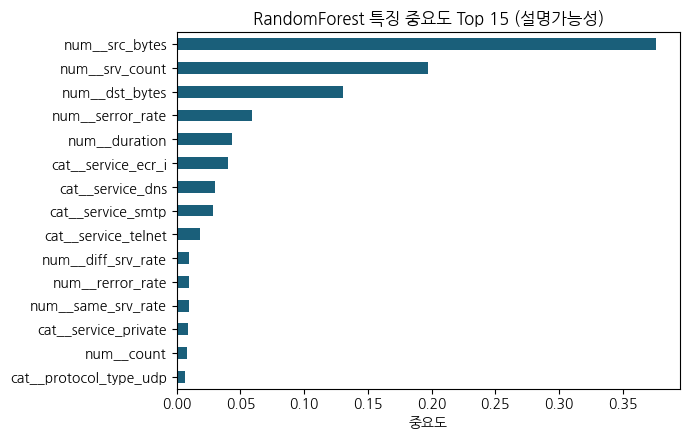

상위 5 피처: ['num__src_bytes', 'num__srv_count', 'num__dst_bytes', 'num__serror_rate', 'num__duration']


In [7]:
# 설명가능성 — RandomForest 가 어떤 피처로 공격을 판단하는가
import matplotlib.pyplot as plt
feat_names = preprocessor.get_feature_names_out()
imp = pd.Series(model3.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 4.5))
imp[::-1].plot(kind='barh', ax=ax, color='#1a5f7a')
ax.set_title('RandomForest 특징 중요도 Top 15 (설명가능성)')
ax.set_xlabel('중요도')
plt.tight_layout(); plt.show()
print('상위 5 피처:', list(imp.head(5).index))

---
## 앙상블·부스팅 — 모델 #4~#5 + Voting/Stacking

단일 모델(LogReg·SVM·RF) 위에 **부스팅(HistGradientBoosting·XGBoost)** 과 **Voting·Stacking** 앙상블을 더해 성능을 비교한다.
- Bagging(분산↓, RF) vs Boosting(편향↓, XGBoost) vs Voting/Stacking(이질 결합)
- 아래 셀에서 model4(HistGB)·model5(XGBoost)·voting·stacking 을 학습하고 test AUC 를 출력한다.


In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier, StackingClassifier

# 모델 #4 — Gradient Boosting (sklearn, 설치 불필요)
model4 = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.1, max_depth=8, random_state=42).fit(X_train, y_train)

# 모델 #5 — XGBoost (미설치 환경이면 HistGB 로 대체)
try:
    from xgboost import XGBClassifier
    neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
    model5 = XGBClassifier(
        n_estimators=400, learning_rate=0.1, max_depth=6, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=neg / pos,
        eval_metric='logloss', random_state=42, n_jobs=-1).fit(X_train, y_train)
except ImportError:
    print('xgboost 미설치 — model5 를 HistGB 로 대체'); model5 = model4

# 이질 모델 결합
voting = VotingClassifier(
    estimators=[('lr', model1), ('rf', model3), ('hgb', model4)],
    voting='soft', n_jobs=-1).fit(X_train, y_train)
stacking = StackingClassifier(
    estimators=[('rf', model3), ('hgb', model4), ('xgb', model5)],
    final_estimator=LogisticRegression(max_iter=1000), n_jobs=-1).fit(X_train, y_train)

for name, m in [('HistGB', model4), ('XGBoost', model5), ('Voting', voting), ('Stacking', stacking)]:
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    print(f'{name:9s}: test AUC={auc:.4f}')


HistGB   : test AUC=0.9573
XGBoost  : test AUC=0.9572
Voting   : test AUC=0.9596
Stacking : test AUC=0.9567


---
## 교차검증과 하이퍼파라미터 튜닝
단일 분할 점수는 분할 운에 좌우된다. StratifiedKFold 교차검증으로 안정 추정하고 GridSearchCV 로 최적 파라미터를 찾는다. SMOTE 는 소수 클래스 오버샘플링(설치 시).


In [9]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.base import clone
cv_pipe = Pipeline([('preprocess', clone(preprocessor)), ('clf', clone(model3))])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = cross_val_score(cv_pipe, df_train[NUM + CAT], y_train, cv=skf, scoring='roc_auc')
print(f'RF CV AUC: {cv.mean():.4f} ± {cv.std():.4f}')

param_grid = {'clf__n_estimators': [200, 400], 'clf__max_depth': [10, 15, 20], 'clf__min_samples_split': [2, 5]}
gs = GridSearchCV(cv_pipe,
                  param_grid, cv=skf, scoring='roc_auc', n_jobs=-1).fit(df_train[NUM + CAT], y_train)
print('best params:', gs.best_params_, '| best CV AUC:', round(gs.best_score_, 4))

# SMOTE 오버샘플링 (imbalanced-learn 설치 시)
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    pipe = ImbPipeline([('preprocess', clone(preprocessor)), ('smote', SMOTE(random_state=42)),
                        ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))])
    f1 = cross_val_score(pipe, df_train[NUM + CAT], y_train, cv=skf, scoring='f1_macro')
    print(f'SMOTE macro-F1: {f1.mean():.4f}')
except ImportError:
    print('imbalanced-learn 미설치 — SMOTE 생략 (pip install imbalanced-learn)')


RF CV AUC: 0.9623 ± 0.0011


best params: {'clf__max_depth': 20, 'clf__min_samples_split': 5, 'clf__n_estimators': 400} | best CV AUC: 0.9625


SMOTE macro-F1: 0.9598


---
## Step 4. ROC-AUC + Confusion Matrix

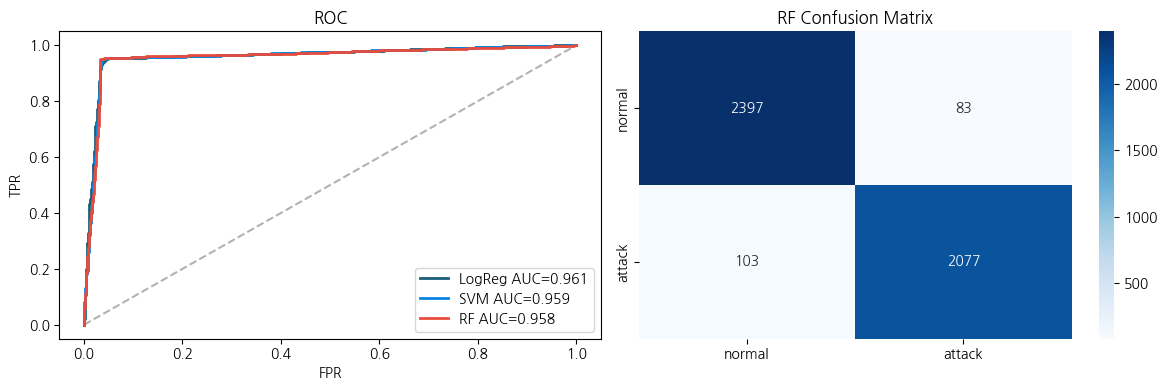

Precision=0.962, Recall=0.953


In [10]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([0,1],[0,1],'k--',alpha=0.3)
for name, m, c in [('LogReg', model1, '#1a5f7a'), ('SVM', model2, '#0984e3'), ('RF', model3, '#e74c3c')]:
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} AUC={roc_auc_score(y_test, proba):.3f}', color=c, linewidth=2)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR'); axes[0].set_title('ROC'); axes[0].legend()

cm = confusion_matrix(y_test, model3.predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['normal','attack'], yticklabels=['normal','attack'])
axes[1].set_title('RF Confusion Matrix')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Precision={tp/(tp+fp):.3f}, Recall={tp/(tp+fn):.3f}')

---
## Step 5. pickle 저장 + 새 데이터 예측

In [11]:
(Path.cwd() / 'models').mkdir(exist_ok=True)
with open(str(Path.cwd() / 'models' / 'nsl_kdd_rf.pickle'), 'wb') as f:
    pickle.dump({'preprocessor': preprocessor, 'model': model3, 'feature_columns': NUM + CAT, 'positive_label': 1}, f)

with open(str(Path.cwd() / 'models' / 'nsl_kdd_rf.pickle'), 'rb') as f:
    saved = pickle.load(f)

# 새 5건 시뮬레이션
new = df_test.sample(5, random_state=99)
X_new = saved['preprocessor'].transform(new[NUM + CAT])
new = new.copy()
new['attack_prob'] = saved['model'].predict_proba(X_new)[:, 1]
new[['protocol_type', 'service', 'flag', 'label_5class', 'attack_prob']]

# 20장에서 같은 보류 표본으로 연결을 확인한다. 운영 성능 평가용 자료는 아니다.
import json
holdout = df_test[NUM + CAT].copy()
prob = saved['model'].predict_proba(saved['preprocessor'].transform(holdout))[:, 1]
rows = []
for route, mask in [('pass', prob < 0.3), ('llm_agent', (prob >= 0.3) & (prob <= 0.9)),
                    ('playbook', prob > 0.9)]:
    indices = np.flatnonzero(mask)
    if len(indices):
        row = json.loads(holdout.iloc[int(indices[0])].to_json())
        rows.append({'expected_route': route, 'features': row})
Path('models/nsl_kdd_holdout.json').write_text(json.dumps(rows, indent=2), encoding='utf-8')
print('20장 연결 확인용 보류 표본:', [r['expected_route'] for r in rows])


20장 연결 확인용 보류 표본: ['pass', 'llm_agent', 'playbook']


## 보완 실습. 학습곡선

14.6.4절과 같은 코드입니다. 전처리는 폴드별로 학습하며 테스트셋은 사용하지 않습니다. 표본 수·트리 깊이에 따른 학습/검증 차이를 비교합니다.

**확인 과제**

1. `max_depth=3`과 기본 설정을 같은 폴드로 비교합니다.
2. 학습·검증 F1의 차이를 표로 기록하고 표본 증가의 효과가 일관적인지 확인합니다.
3. 이 과정에서 최종 테스트셋을 사용하지 않는 이유를 설명합니다.

In [12]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import learning_curve, StratifiedKFold

curve_model = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', RandomForestClassifier(n_estimators=50, random_state=42,
                                     class_weight='balanced', n_jobs=1)),
])
sizes, train_scores, valid_scores = learning_curve(
    curve_model, df_train[NUM + CAT], df_train['label_bin'],
    train_sizes=[0.2, 0.5, 1.0],
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring='f1', shuffle=True, random_state=42, n_jobs=1,
)
curve = pd.DataFrame({'학습 표본 수': sizes,
                      '학습 F1': train_scores.mean(axis=1),
                      '검증 F1': valid_scores.mean(axis=1)})
print(curve.round(3).to_string(index=False))


 학습 표본 수  학습 F1  검증 F1
    2526  0.999  0.957
    6316  0.999  0.957
   12633  0.999  0.958


---
## 정리
- KISIA Part 5 의 5단계 프레임이 보안 데이터에 그대로 적용된다.
- RF 가 일반적으로 가장 좋은 기준 모델.
- pickle 로 전처리기·모델을 함께 저장하면 운영 시 일관성 보장.